# Why do analogs launch late?

`late_launch` flags analogs whose first Medicaid (SDUD) quarter is more than 4 quarters after the brand's first approval. A late start can mean three different things, and only one of them is a slow uptake curve:

1. **Route added later**: the route group's own application was approved years after the brand (e.g. an sc version of an IV drug). The curve is real, but it's not a first launch.
2. **Commercial launch delayed**: the route group was approved on time, but the product wasn't marketed for > 4 quarters (start marketing date in the NDC Directory).
3. **Medicaid uptake slow**: marketed on time, but Medicaid fills only started > 4 quarters later.

Dates compared, all in quarters after the brand's first approval: the route group's own application approval (`indication_history`, ORIG), the earliest NDC start marketing date (`candidate_pool`), and the launch quarter (first SDUD quarter, `analog_features`).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "pipeline").exists() else Path.cwd().parent
PROCESSED = ROOT / "data" / "processed"
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 60)

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0"
COLORS = {"route application approved": "#2a78d6", "start marketing": "#eb6834", "first Medicaid quarter": "#1baf7a"}
LATE = 4  # quarters, same threshold as late_launch


def qnum(iso):
    """'2019-04-23' -> quarter number; '2019Q2' too."""
    if pd.isna(iso):
        return float("nan")
    iso = str(iso)
    if "Q" in iso:
        return int(iso[:4]) * 4 + int(iso[-1]) - 1
    return int(iso[:4]) * 4 + (int(iso[5:7]) - 1) // 3

In [2]:
f = pd.read_csv(PROCESSED / "analog_features.csv")
cp = pd.read_csv(PROCESSED / "candidate_pool.csv")
h = pd.read_csv(PROCESSED / "indication_history.csv")

route_app = (h[(h.kind == "original") & (h.submission_type == "ORIG")]
             .groupby("analog_id").approval_date.min().rename("route_app_date"))
d = (cp[["analog_id", "brand_name", "route_group", "application_number", "submission_class", "dosage_form",
         "approval_date", "start_marketing_date", "n_route_groups"]]
     .merge(f[["analog_id", "launch_quarter", "late_launch", "multi_route", "quarters_of_data"]], on="analog_id")
     .join(route_app, on="analog_id"))

base = d.approval_date.map(qnum)
d["q_route_app"] = d.route_app_date.map(qnum) - base
d["q_start_marketing"] = d.start_marketing_date.map(qnum) - base
d["q_first_medicaid"] = d.launch_quarter.map(qnum) - base
d["q_marketing_to_medicaid"] = d.q_first_medicaid - d.q_start_marketing

d["reason"] = "Medicaid uptake slow"
d.loc[d.q_start_marketing > LATE, "reason"] = "commercial launch delayed"
d.loc[d.q_route_app > LATE, "reason"] = "route added later"

late = d[d.late_launch == True].sort_values(["reason", "q_first_medicaid"])
print(f"{len(late)} late launches")
late.reason.value_counts().to_frame("analogs")

19 late launches


,analogs
reason,
Medicaid uptake slow,10
commercial launch delayed,6
route added later,3


## The 19 late launches

In [3]:
cols = ["analog_id", "reason", "submission_class", "dosage_form", "approval_date", "route_app_date",
        "start_marketing_date", "launch_quarter", "q_route_app", "q_start_marketing", "q_first_medicaid",
        "q_marketing_to_medicaid"]
late[cols].reset_index(drop=True)

,analog_id,reason,submission_class,dosage_form,approval_date,route_app_date,start_marketing_date,launch_quarter,q_route_app,q_start_marketing,q_first_medicaid,q_marketing_to_medicaid
0,fycompa_oral,Medicaid uptake slow,Type 1 - New Molecular Entity,SUSPENSION; TABLET,2012-10-22,2012-10-22,2012-10-22,2014Q1,0,0,5.0,5.0
1,xolremdi_oral,Medicaid uptake slow,Type 1 - New Molecular Entity,"CAPSULE, GELATIN COATED",2024-04-26,2024-04-26,2024-05-21,2025Q4,0,0,6.0,6.0
2,sirturo_oral,Medicaid uptake slow,Type 1 - New Molecular Entity,TABLET,2012-12-28,2012-12-28,2012-12-28,2014Q3,0,0,7.0,7.0
3,bevyxxa_oral,Medicaid uptake slow,Type 1 - New Molecular Entity,NaN,2017-06-23,2017-06-23,2017-07-07,2019Q3,0,1,9.0,8.0
4,exxua_oral,Medicaid uptake slow,Type 1 - New Molecular Entity,"TABLET, EXTENDED RELEASE",2023-09-22,2023-09-22,2024-01-01,2025Q4,0,2,9.0,7.0
5,ibsrela_oral,Medicaid uptake slow,Type 1 - New Molecular Entity,TABLET,2019-09-12,2019-09-12,2019-09-12,2022Q2,0,0,11.0,11.0
6,impavido_oral,Medicaid uptake slow,Type 1 - New Molecular Entity,CAPSULE,2014-03-19,2014-03-19,2014-09-19,2017Q1,0,2,12.0,10.0
7,aemcolo_oral,Medicaid uptake slow,Type 1 - New Molecular Entity,NaN,2018-11-16,2018-11-16,2019-02-01,2021Q4,0,1,12.0,11.0
8,scenesse_sc,Medicaid uptake slow,Type 1 - New Molecular Entity,IMPLANT,2019-10-08,2019-10-08,2019-12-31,2023Q2,0,0,14.0,14.0
9,kybella_sc,Medicaid uptake slow,Type 1 - New Molecular Entity,"INJECTION, SOLUTION",2015-04-29,2015-04-29,2015-06-08,2022Q1,0,0,27.0,27.0


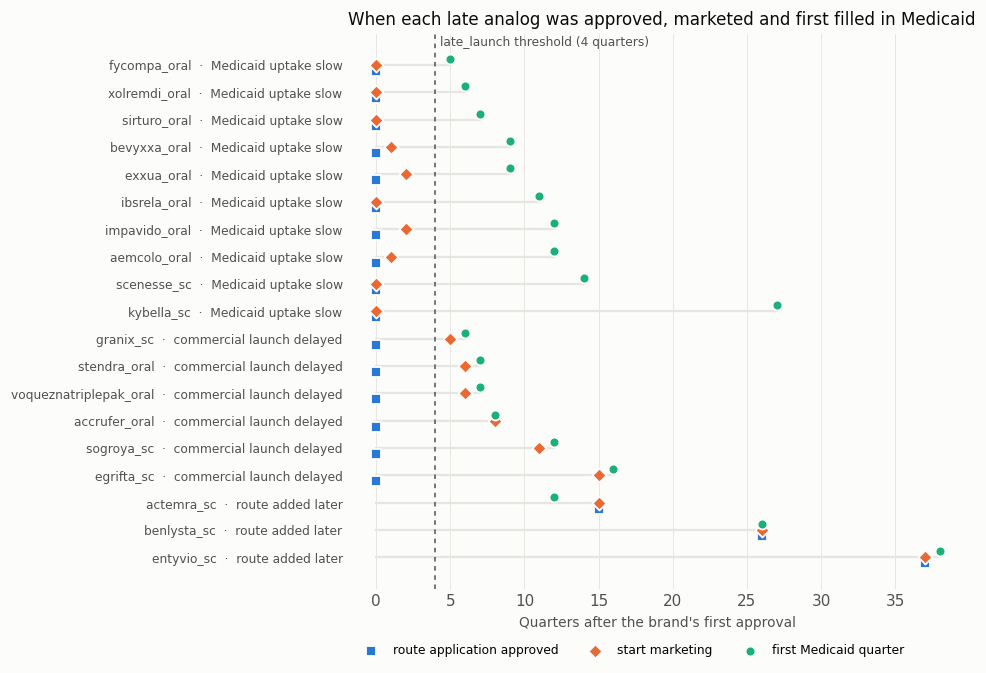

In [4]:
fig, ax = plt.subplots(figsize=(9, 6.2), dpi=110)
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)
rows = late.iloc[::-1].reset_index(drop=True)
for i, r in rows.iterrows():
    pts = [r.q_route_app, r.q_start_marketing, r.q_first_medicaid]
    ax.plot([0, max(p for p in pts if p == p)], [i, i], color=GRID, linewidth=1.5, zorder=1)
# small vertical offsets so markers on the same quarter don't hide each other
for (label, color), col, marker, dy in zip(COLORS.items(), ["q_route_app", "q_start_marketing", "q_first_medicaid"],
                                           ["s", "D", "o"], [-0.22, 0, 0.22]):
    ax.scatter(rows[col], rows.index + dy, s=42, color=color, marker=marker, label=label, zorder=3,
               edgecolor=SURFACE, linewidth=1.2)
ax.axvline(LATE, color=INK2, linewidth=1, linestyle=(0, (3, 3)))
ax.text(LATE + 0.3, len(rows) - 0.4, "late_launch threshold (4 quarters)", fontsize=8, color=INK2, va="bottom")
ax.set_yticks(rows.index, [f"{a}  ·  {r}" for a, r in zip(rows.analog_id, rows.reason)], fontsize=8)
ax.set_xlabel("Quarters after the brand's first approval", color=INK2, fontsize=9)
ax.set_title("When each late analog was approved, marketed and first filled in Medicaid", loc="left",
             fontsize=11, color=INK)
ax.tick_params(colors=INK2, length=0)
ax.grid(axis="x", color=GRID, linewidth=0.6)
ax.set_axisbelow(True)
for s in ax.spines.values():
    s.set_visible(False)
ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.08), frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

## Check the NDCs behind each late analog

A late start marketing date can also mean `ndc_map` is missing the launch-era NDCs (delisted products often drop out of the NDC Directory). Earliest start marketing date and NDC count by listing source:

In [5]:
n = pd.read_csv(PROCESSED / "ndc_map.csv", dtype={"start_marketing_date": "Int64"})
nl = n[n.analog_id.isin(late.analog_id)]
(nl.groupby(["analog_id", "listing"])
   .agg(ndcs=("ndc9", "size"), earliest_start=("start_marketing_date", "min"),
        applications=("application_number", lambda s: "; ".join(sorted(s.dropna().unique()))),
        dosage_forms=("dosage_form", lambda s: "; ".join(sorted(s.dropna().unique()))))
   .reset_index())

,analog_id,listing,ndcs,earliest_start,applications,dosage_forms
0,accrufer_oral,current,1,20210701,NDA212320,CAPSULE
1,actemra_sc,current,2,20131021,BLA125472,"INJECTION, SOLUTION"
2,aemcolo_oral,excluded,3,20190201,NDA210910,
3,benlysta_sc,current,1,20170720,BLA761043,SOLUTION
4,bevyxxa_oral,excluded,2,20170707,NDA208383,
5,egrifta_sc,current,2,20191104,BLA022505,KIT
6,egrifta_sc,excluded,1,20140714,BLA022505,
7,entyvio_sc,current,2,20230927,BLA761133,"INJECTION, SOLUTION"
8,exxua_oral,current,4,20251001,NDA021164,"TABLET, EXTENDED RELEASE"
9,exxua_oral,excluded,4,20240101,NDA021164,


## Launches with a late start marketing date that aren't flagged

`checks.md` lists 15 analogs whose start marketing date is > 1 year after approval, but `late_launch` only covers analogs with Medicaid data. The ones missing from the flag:

In [6]:
late_mkt = d[(d.q_start_marketing > LATE) & (d.late_launch != True)]
late_mkt[["analog_id", "reason", "approval_date", "route_app_date", "start_marketing_date", "launch_quarter",
          "q_route_app", "q_start_marketing"]].reset_index(drop=True)

,analog_id,reason,approval_date,route_app_date,start_marketing_date,launch_quarter,q_route_app,q_start_marketing
0,ozempic_oral,route added later,2017-12-05,2019-09-20,2026-04-27,NaN,7,34
1,moxidectin_oral,commercial launch delayed,2018-06-13,2018-06-13,2019-12-02,NaN,0,6
2,saphnelo_sc,route added later,2021-07-30,2026-04-24,2026-04-24,NaN,19,19
3,spevigo_sc,commercial launch delayed,2022-09-01,2022-09-01,2026-03-09,NaN,0,14
4,lunsumio_sc,commercial launch delayed,2022-12-22,2022-12-22,2025-12-19,NaN,0,12
5,zegfrovy_oral,commercial launch delayed,2025-07-02,2025-07-02,2026-10-22,NaN,0,5


## Late Medicaid uptake vs everyone else

Quarters from start marketing to the first Medicaid quarter, across the whole pool (analogs with Medicaid data and a start marketing date on or after approval):

In [7]:
ok = d[d.q_marketing_to_medicaid.notna() & (d.q_start_marketing >= 0)]
ok.q_marketing_to_medicaid.clip(upper=12).value_counts().sort_index().rename("analogs").to_frame().T

q_marketing_to_medicaid,-3.0,-2.0,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,10.0,11.0,12.0
analogs,1,1,193,158,28,11,3,1,1,2,1,1,2,2


## Takeaways

- **Route added later (3): Actemra sc, Benlysta sc, Entyvio sc.** Their sc applications came 4–9 years after the IV brand. These curves are line extensions into an established market, not first launches; consider leaving them out of the analog pool. Actemra sc's first Medicaid quarter (2013Q1) is *before* its sc application was approved (2013-10): check which NDC has that row.
- **Commercial launch delayed (6): Granix, Stendra, Voquezna Triple Pak, Accrufer, Sogroya, Egrifta.** The launch quarter (first SDUD quarter) already starts the curve at the real launch, so these curves look usable. **Egrifta** is the exception to check: its earliest NDC in `ndc_map` is a 2014 listing, but the brand was approved in 2010, so its launch-era NDCs may be missing and the curve may start mid-life.
- **Medicaid uptake slow (10).** The NDC start marketing date isn't always the launch date: **Fycompa** is listed on approval day, but as a controlled substance it likely waited for DEA scheduling (verify). Most of the rest are drugs Medicaid rarely pays for or that are supplied outside retail pharmacy: **Kybella** (cosmetic), **Scenesse** (implant placed in clinic), **Impavido, Sirturo, Aemcolo** (tropical disease, TB, travellers' diarrhoea). Their Medicaid curves don't represent uptake; exclude them.
- **Missing from the flag (6):** analogs with a late start marketing date but no Medicaid data yet. Ozempic oral and Saphnelo sc are routes added later; **Spevigo sc and Lunsumio sc** are sc forms added under the brand's original BLA, which this classification can't see (it reads the application's ORIG date), so they show as "commercial launch delayed".
- **Across the pool**, 351 of 405 analogs have their first Medicaid fill in the start marketing quarter or the next one, so the 4-quarter threshold only catches the real tail.